### Goals

- load models trained with different setups
- with each model, predict the test set  
- compute metrics







In [6]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm

import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [7]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics


### Examples of how to filter wandb runs:

example_filters = {


    "group" : "17/5 single-bi-trimodal",
    "config.image_encoder.use": True,
    "config.batch_size": {'$gt': 10}, #Greater than
    "config.batch_size": {'$lte': 10}, #Less than or equal
    
	"$and": [{
		'created_at': {
			"$lt": '2022-03-09T10',
			"$gt": '2022-03-07T17'
		}
	}]
    
}

In [8]:
# Define the filter criteria
'''filter_criteria = {
    'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    
    "group" : "25/5 eval freezing enc, modalities, n of examples",
    "config.seed" : 420,
    "$or": [{
        'config.train_examples_per_class': {
            "$gt": '200',
        }
    },
        {
        'config.train_examples_per_class': {
            "$lt": '200',
        }
    }
    ]
}'''


'filter_criteria = {\n    \'config.image_encoder.use\': True,\n    #\'config.tabular_encoder.use\': True,\n    #\'config.loc_encoder.use\': True,\n    \n    "group" : "25/5 eval freezing enc, modalities, n of examples",\n    "config.seed" : 420,\n    "$or": [{\n        \'config.train_examples_per_class\': {\n            "$gt": \'200\',\n        }\n    },\n        {\n        \'config.train_examples_per_class\': {\n            "$lt": \'200\',\n        }\n    }\n    ]\n}'

In [19]:
# Define the filter criteria
filter_criteria = {
    'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    
    "group" : "18/6 dst 5, new split",
    "config.seed" : 420,


    
}





In [20]:
models = utils.get_wandb_runs(filter_criteria)

print(f'models: {len(models)}')

models: 17


In [54]:
models[0]['wandb_id']

'amxod7tf'

In [6]:
'''
In some cases, the wandb API filtering doesn't work;
If I get 0 models returned, I need to 
    1. remove the problematic filter
    2. get all the runs
    3. filter manually as below
'''
#Example:
selected_models = [model for model in models  if model['config']['train dst size'] > 10000]  
#print(len(selected_models))
#models = selected_models

"\nIn some cases, the wandb API filtering doesn't work;\nIf I get 0 models returned, I need to \n    1. remove the problematic filter\n    2. get all the runs\n    3. filter manually as below\n"

In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 12


In [17]:
for model_dict in tqdm.tqdm(models):

    metrics, preds = utils.load_model_and_predict(model_dict, n_classes, device, 'test')
    model_dict['predictions'] = preds
    model_dict['metrics'] = metrics
    
    #This is just to get rid of wandb objects that are un-picklable wtf
    model_dict['summary'] = dict(model_dict['summary'])
    model_dict['summary']['_wandb'] = dict(model_dict['summary']['_wandb'])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 48/48 [00:00<00:00, 89877.94it/s]


In [11]:
#selected_models = [model for model in models  if model['config']['train_examples_per_class'] < 1000]  


48

In [15]:
def inspect_objects(d, path=""):
    if isinstance(d, dict):
        for k, v in d.items():
            new_path = f"{path}/{k}" if path else str(k)
            inspect_objects(v, new_path)
    elif isinstance(d, list):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    elif isinstance(d, tuple):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    else:
        print(f"Object at path {path}: {type(d)}")

In [19]:
import pickle
with open('18_6.pickle', 'wb') as handle:
    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [20]:
#with open('filename.pickle', 'rb') as handle:
#    first_set = pickle.load(handle)
with open('18_6.pickle', 'rb') as handle:
    test = pickle.load(handle)


In [44]:
import importlib
importlib.reload(utils)


<module 'utils' from '/home/jan/Documents/EPFL/project_2/notebooks/../utils.py'>

In [21]:
hyperparams_values = utils.find_keys_with_multiple_values([model['config'] for model in models])

In [24]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_grid_5_split.csv")
labels = labels.loc[labels['split'] == 4 ].reset_index(drop=True) # Get test examples 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()


In [25]:
def get_models_with_config(_models, target_config):
    
    def has_key_value_pair(d, target):
        if isinstance(d, dict) and isinstance(target, dict):
            for key, value in target.items():
                if key in d:
                    if isinstance(value, dict) and isinstance(d[key], dict):
                        if not has_key_value_pair(d[key], value):
                            return False
                    else:
                        if d[key] != value:
                            return False
                else:
                    return False
            return True
        return d == target
    
    models_with_this_config_combination = []
    for model in _models:
        skip_model = False
        for key in target_config.keys():
            if not has_key_value_pair(model['config'][key],target_config[key]):
            #if model['config'][key] != target_config[key]:
                skip_model = True
                break
        if skip_model:
            continue
        models_with_this_config_combination.append(model)
    
    return models_with_this_config_combination

In [26]:
exclude_keys = ['seed']

combinations = utils.generate_combinations(hyperparams_values, exclude_keys)

In [27]:
hyperparams_values

{'loc_encoder': {'use': [False, True]},
 'folds_to_split': {'mapping': [(('0', 'val'),
    ('1', 'train'),
    ('2', 'train'),
    ('3', 'train'),
    ('4', 'test')),
   (('0', 'train'),
    ('1', 'train'),
    ('2', 'val'),
    ('3', 'train'),
    ('4', 'test')),
   (('0', 'train'),
    ('1', 'train'),
    ('2', 'train'),
    ('3', 'val'),
    ('4', 'test')),
   (('0', 'train'),
    ('1', 'val'),
    ('2', 'train'),
    ('3', 'train'),
    ('4', 'test'))]},
 'tabular_encoder': {'use': [False, True]},
 'train_examples_per_class': [200, 50, 20]}

In [28]:
len(combinations)

12

In [29]:
from pprint import pformat

In [30]:
#This I need to do in case there is only 1 seed
hyperparams_values['seed'] = [420]

In [31]:

performance_per_configuration = {}

for combo in combinations:
    
    metrics_per_random_seed = []
    
    combo_str = ' '.join(pformat(combo, width=1).split())
    
    #Compute metrics per each random seed separately
    for seed in hyperparams_values['seed']:
        combo['seed'] = seed 
        
        #Get all models that have the configuration setup 
        model_with_this_config = get_models_with_config(models, combo)
        if not models_with_this_config:
            continue
            
        assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"


        metrics_per_random_seed.append(pd.DataFrame(model_with_this_config['metrics']))


    if not metrics_per_random_seed:
        print("no metrics for: ", combo)
        continue


    # Concatenate DataFrames along a new axis
    concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

    # Compute the mean along the new axis
    mean_df = concat_df.groupby(level=1).mean()

    # Compute the standard deviation along the new axis
    std_df = concat_df.groupby(level=1).std()   
    
    

    performance_per_configuration[combo_str] = {}
    performance_per_configuration[combo_str]['mean'] = mean_df
    performance_per_configuration[combo_str]['std'] = std_df



        

dict_keys(["{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 200}", "{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 50}", "{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 20}", "{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_examples_per_class': 200}", "{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_examples_per_class': 50}", "{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_examples_per_class': 20}", "{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 200}", "{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 50}", "{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 20}", "{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_e

In [43]:
#frozen_img_enc_models = {key:value for key, value in performance_per_configuration.items() if "'freeze_after': 6" in key}

models_20_per_class = {key:value for key, value in performance_per_configuration.items() if "'train_examples_per_class': 20}" in key}
models_50_per_class = {key:value for key, value in performance_per_configuration.items() if "'train_examples_per_class': 50}" in key}
models_200_per_class = {key:value for key,value in performance_per_configuration.items() if "'train_examples_per_class': 200}" in key}




In [ ]:
import matplotlib.pyplot as plt


In [39]:
def plot_metrics(metrics):
    
    class_names = list(LABEL_MAPPING.keys())
    class_names.append('accuracy')
    stats = {}
    for model_name, model_stats in metrics.items():
        stats[model_name] = {}
        for cls in class_names:
            stats[model_name][cls] = {}
            stats[model_name][cls]['score'] = metrics[model_name]['mean'][cls]['f1-score']
            stats[model_name][cls]['std'] = metrics[model_name]['std'][cls]['f1-score']

    # Initialize plot
    fig, ax = plt.subplots(figsize=(12, 6))

    # Set the width of the bars
    bar_width = 0.7/len(metrics)

    # Set positions of the bars on the x-axis
    index = np.arange(len(class_names))

    # Plot each model's data

    #for i, model in enumerate(stats.keys()):
    for i, model in enumerate(list(metrics.keys())): #only models with image
        scores = [stats[model][cls]['score'] for cls in class_names]
        stds = [stats[model][cls]['std'] for cls in class_names]
        ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

    # Set labels, title, and legend
    #ax.set_xlabel('Class')
    #ax.set_ylabel('Score')
    plt.ylim(bottom=0.2)
    plt.ylim(top=1)
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.legend()

    # Show plot
    plt.tight_layout()
    plt.show()

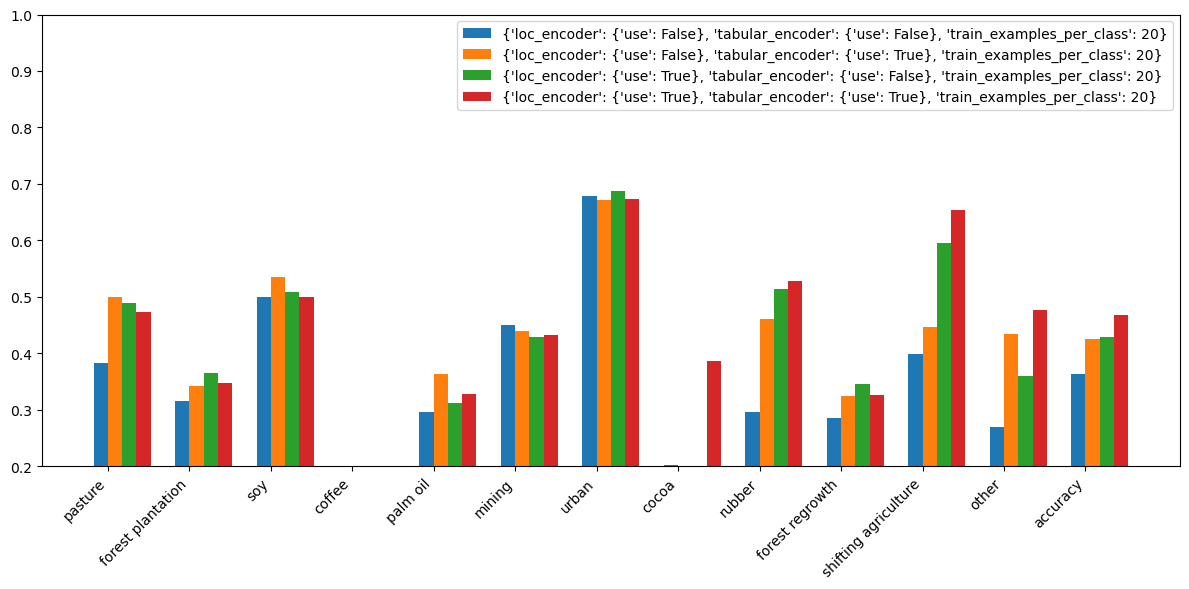

In [45]:
plot_metrics(models_20_per_class)

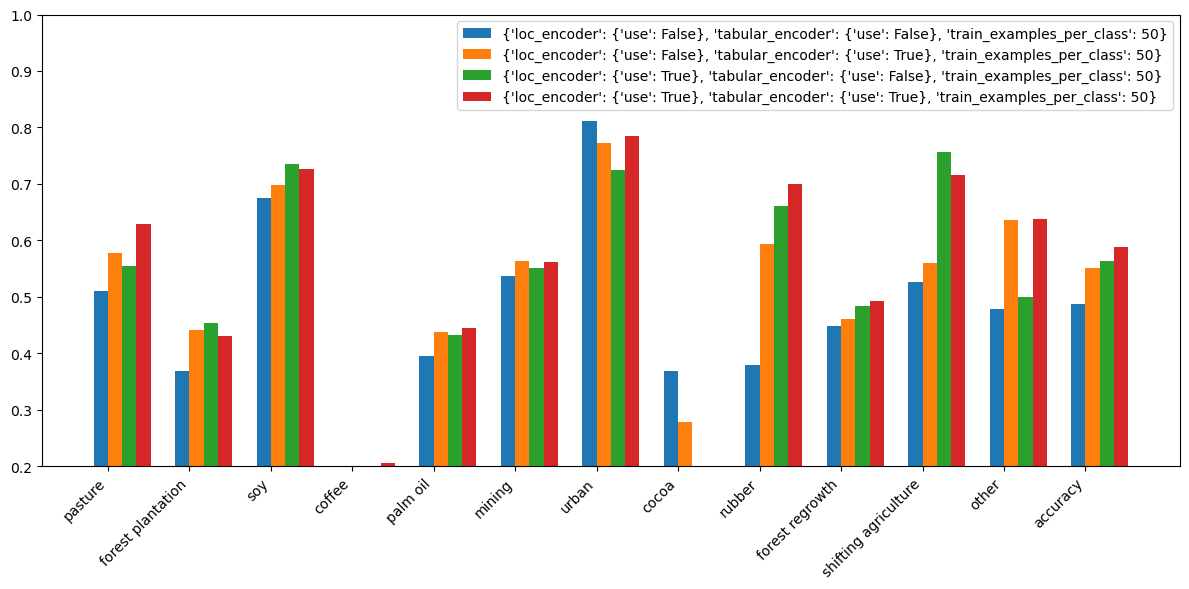

In [46]:
plot_metrics(models_50_per_class)

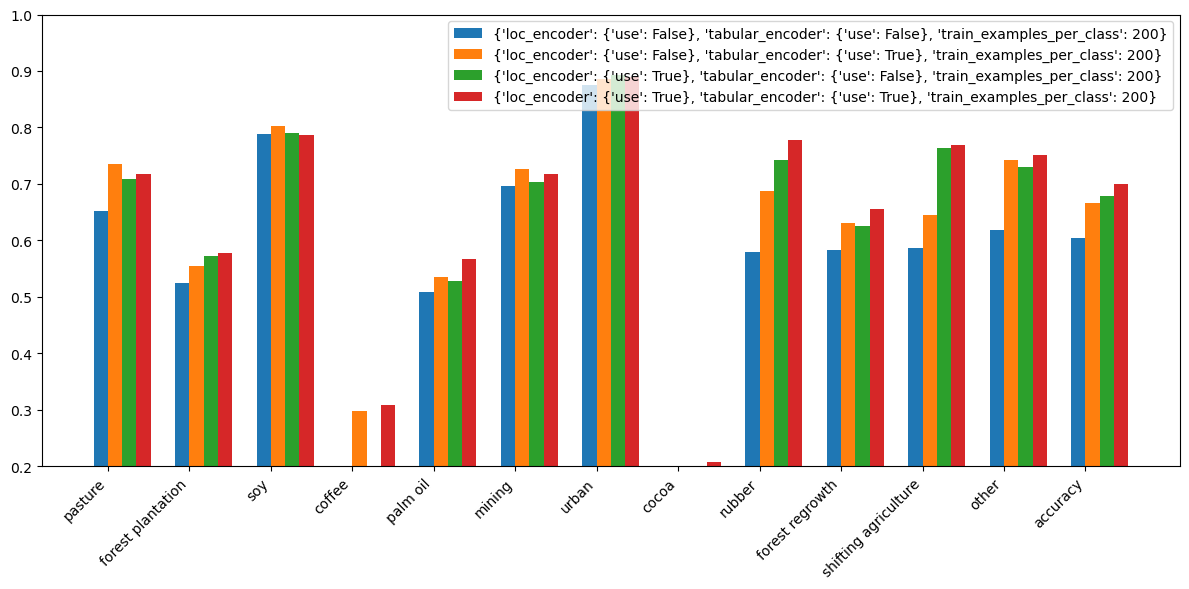

In [47]:
plot_metrics(models_200_per_class)

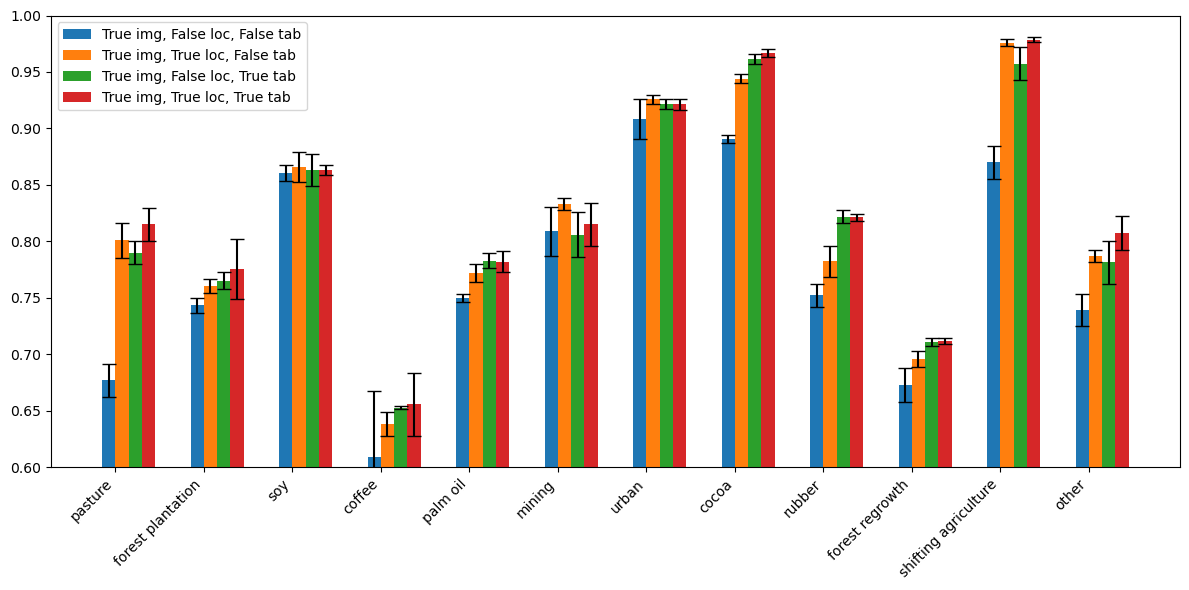

In [195]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(list(performance_per_configuration.keys())): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.6)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

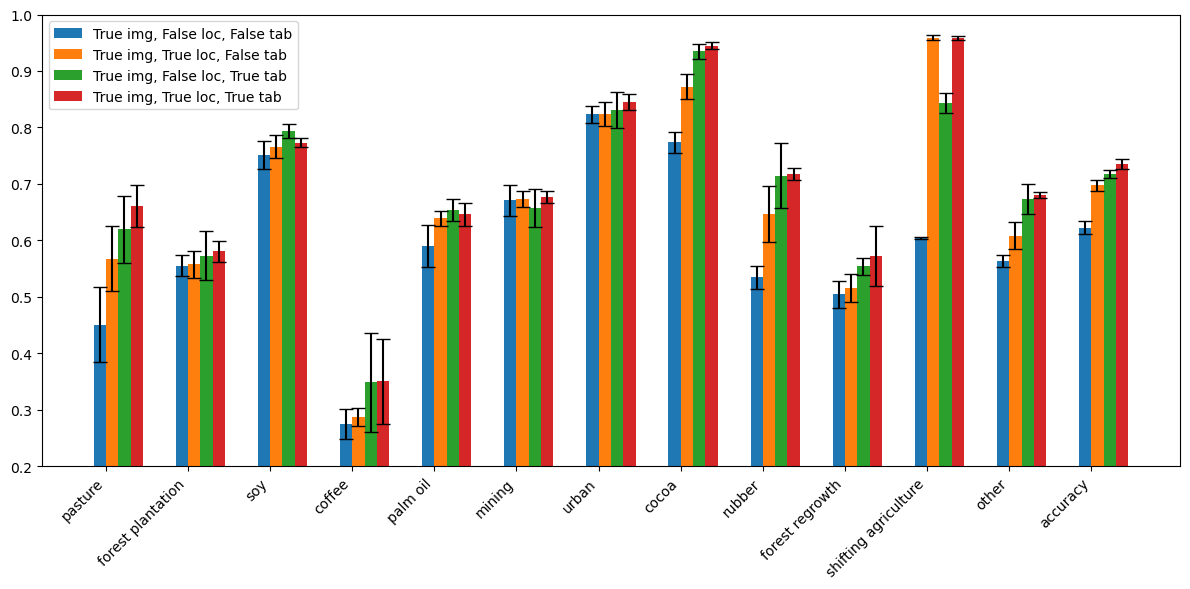

In [44]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(img_only_reordered): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.2)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()